# Hillstrom Email Marketing Experiment — Starter Notebook
**Applied Statistics and Data Science I · EN.553.413/613**

**Source:** [Kevin Hillstrom's MineThatData E-Mail Analytics Challenge (2008)](https://blog.minethatdata.com/2008/03/)

64,000 customers who had bought something in the past 12 months were randomly assigned to one of three groups: they received a **Men's** merchandise email, a **Women's** merchandise email, or **no email**. Their activity was then tracked for the two weeks after the campaign.

| Column | Description |
|---|---|
| `recency` | Months since last purchase |
| `history_segment` | Binned dollars spent in the past year |
| `history` | Dollars spent in the past year |
| `mens` | 1 = bought men's merchandise in the past year |
| `womens` | 1 = bought women's merchandise in the past year |
| `zip_code` | Urban, Suburban, or Rural (spelled `Surburban` in the raw data) |
| `newbie` | 1 = new customer in the past 12 months |
| `channel` | Channels the customer bought from in the past year (Phone, Web, Multichannel) |
| `segment` | Assigned group: Mens E-Mail, Womens E-Mail, No E-Mail |
| `visit` | 1 = visited the website in the following two weeks |
| `conversion` | 1 = made a purchase in the following two weeks |
| `spend` | Dollars spent in the following two weeks |

This notebook only loads the data and makes a few basic plots. The analysis is up to you.

> The first run downloads the data (internet required) and saves it in a local `data/` folder.

## 1. Load the data

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import requests

DATA = Path('data')
DATA.mkdir(exist_ok=True)
CSV_PATH = DATA / 'hillstrom_2008.csv'
URL = 'https://raw.githubusercontent.com/AdityaDabrase/ab-testing-email-marketing/main/data/raw/hillstrom.csv'

if not CSV_PATH.is_file():
    r = requests.get(URL, timeout=120)
    r.raise_for_status()
    CSV_PATH.write_bytes(r.content)

df = pd.read_csv(CSV_PATH)
print(df.shape)
df.head()

(64000, 12)


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [3]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
recency,64000.0,NaN,NaN,NaN,5.763734,3.507592,1.0,2.0,6.0,9.0,12.0
history_segment,64000,7,1) $0 - $100,22970,NaN,NaN,NaN,NaN,NaN,NaN,NaN
history,64000.0,NaN,NaN,NaN,242.085656,256.158608,29.99,64.66,158.11,325.6575,3345.93
mens,64000.0,NaN,NaN,NaN,0.551031,0.497393,0.0,0.0,1.0,1.0,1.0
womens,64000.0,NaN,NaN,NaN,0.549719,0.497526,0.0,0.0,1.0,1.0,1.0
zip_code,64000,3,Surburban,28776,NaN,NaN,NaN,NaN,NaN,NaN,NaN
newbie,64000.0,NaN,NaN,NaN,0.50225,0.499999,0.0,0.0,1.0,1.0,1.0
channel,64000,3,Web,28217,NaN,NaN,NaN,NaN,NaN,NaN,NaN
segment,64000,3,Womens E-Mail,21387,NaN,NaN,NaN,NaN,NaN,NaN,NaN
visit,64000.0,NaN,NaN,NaN,0.146781,0.35389,0.0,0.0,0.0,0.0,1.0


## 2. A first look

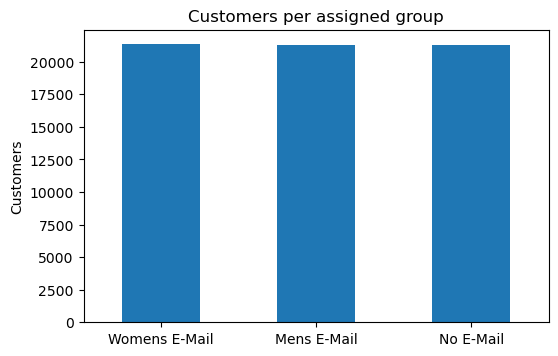

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.8))
df['segment'].value_counts().plot.bar(ax=ax, rot=0)
ax.set(xlabel='', ylabel='Customers', title='Customers per assigned group')
plt.show()

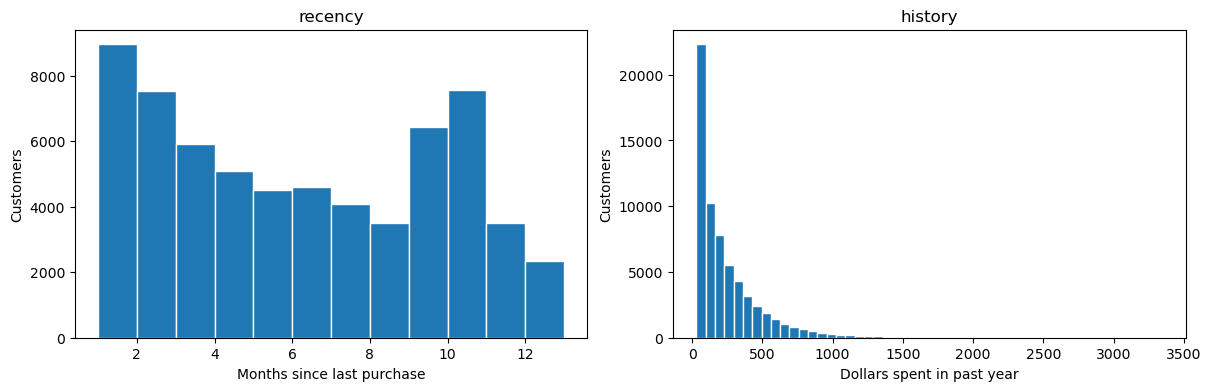

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
axs[0].hist(df['recency'], bins=range(1, 14), edgecolor='white')
axs[0].set(xlabel='Months since last purchase', ylabel='Customers', title='recency')
axs[1].hist(df['history'], bins=50, edgecolor='white')
axs[1].set(xlabel='Dollars spent in past year', ylabel='Customers', title='history')
plt.show()

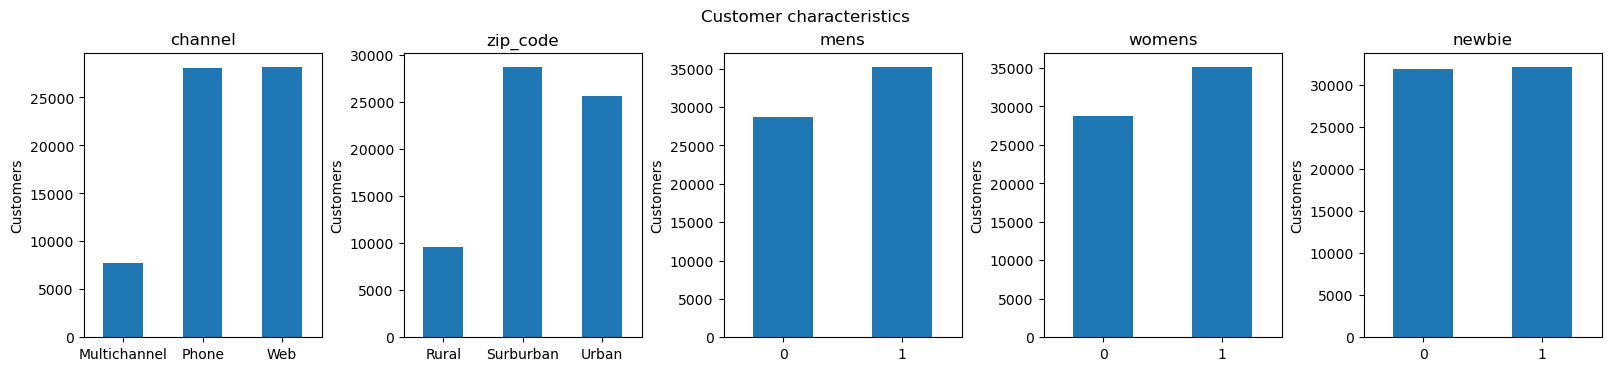

In [6]:
cats = ['channel', 'zip_code', 'mens', 'womens', 'newbie']
fig, axs = plt.subplots(1, 5, figsize=(16, 3.6), constrained_layout=True)
for ax, col in zip(axs, cats):
    df[col].value_counts().sort_index().plot.bar(ax=ax, rot=0)
    ax.set(title=col, xlabel='', ylabel='Customers')
fig.suptitle('Customer characteristics')
plt.show()

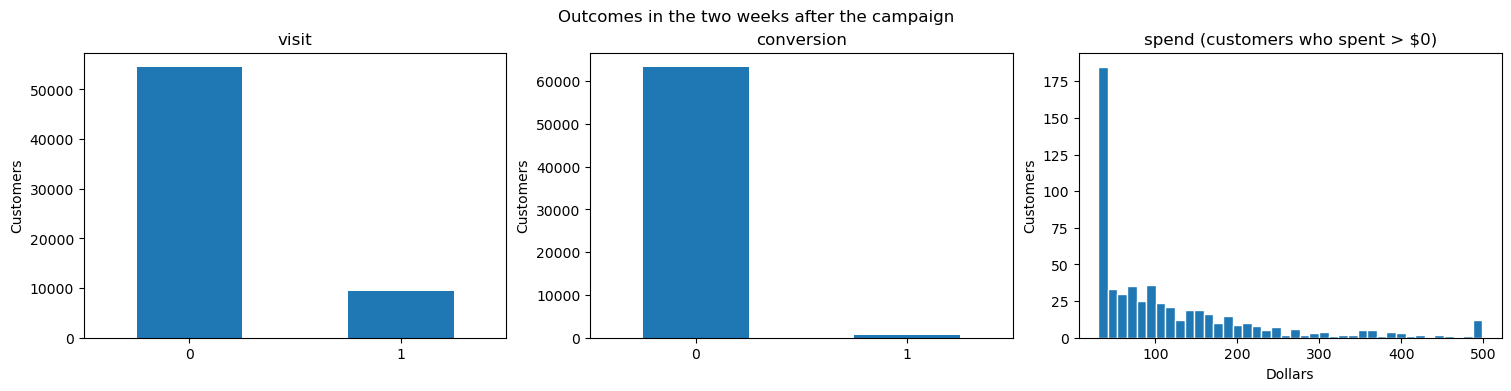

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), constrained_layout=True)
for ax, col in zip(axs[:2], ['visit', 'conversion']):
    df[col].value_counts().sort_index().plot.bar(ax=ax, rot=0)
    ax.set(title=col, xlabel='', ylabel='Customers')
axs[2].hist(df.loc[df['spend'] > 0, 'spend'], bins=40, edgecolor='white')
axs[2].set(xlabel='Dollars', ylabel='Customers', title='spend (customers who spent > $0)')
fig.suptitle('Outcomes in the two weeks after the campaign')
plt.show()

## 3. Your exploration
Add your own analysis below.